Dataset Seçim Kontrolü
1.  Dataset ne hakkında?

1912 yılındaki Titanic faciasında yer alan yolcuların demografik, bilet ve seyahat bilgilerini ve hayatta kalma durumlarını içerir.

2.  Kaç satır ve sütun var?

Standart eğitim setinde 891 satır ve 12 sütun bulunmaktadır (Kodda PassengerId indekse alındığı için veri çerçevesi 891 satır, 11 sütun olarak işlenmektedir)

3.  Target var mı?

Target Survived değişkenidir (0: Hayatta kalamadı, 1: Hayatta kaldı).

4.  Problem classification mı, regression mı, başka bir tür mü?

İkili sınıflandırma (Binary Classification) problemidir.

5.  Eksik değer var mı?

Evet. Age, Cabin ve Embarked sütunlarında eksik değerler bulunmaktadır.

6.  Kişisel / hassas veri içeriyor mu?

Tarihî ve açık kaynaklı bir veri setidir. Kişisel/ hassas veri içermez.

7.  Kaynağı güvenilir ve belli mi?

Kaggle'da açık ve doğrulanmış bir kaynaktır.

8.  Lisans / kullanım koşulu uygun mu?

Evet. Kamuya açık, eğitim ve araştırma amaçlı kullanıma tamamen uygundur.

9.  Boyutu başlangıç seviyesi için yönetilebilir mi?

Evet. Boyutu 1 MB'ın altındadır, CPU ve Colab ortamında hızlıca işlenebilir.

10.  Bu haftanın öğrenme hedefine gerçekten uygun mu?

Kategorik, sayısal ve hedef değişken dengesi barındırdığı için dağılım, aykırı değer analizi ve görselleştirme hedeflerine birebir uygundur.

KURULUM VE VERİ YÜKLEME

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Grafiklerin düzgün görüntülenmesi ve genel stili sağlar
sns.set_theme(style = "whitegrid")
plt.rcParams["figure.figsize"] = (10,6)

# Titanic verisini GitHub üzerinden Pandas ile yüklüyoruz
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
dataset = pd.read_csv(url, index_col="PassengerId")

print("Titanic Verisi Başarıyla Yüklendi. İlk 5 Satır: ")
display(dataset.head())

print("Satır ve Sütun Sayısı:", dataset.shape)

Titanic Verisi Başarıyla Yüklendi. İlk 5 Satır: 


,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Satır ve Sütun Sayısı: (891, 11)


1-TEMİZLEME ADIMLARI

In [ ]:
# -Eksik değer kontrolü (Age sütunu için)-
print("Age temizleme öncesi eksik değer sayısı")
print(dataset["Age"].isnull().sum())

# Yaş sütunundaki eksikleri medyan ile dolduruyoruz
dataset["Age"] = dataset['Age'].fillna(dataset["Age"].median())

print("Temzileme sonrası eksik değer sayısı")
print(dataset["Age"].isnull().sum())

print("-" * 50)

# -Embarked (Biniş Limanı) Kontrolü-
print("Temizleme öncesi dağılım")
print(dataset["Embarked"].value_counts(dropna=False))

# En çok biniş yapılan liman (mod) ile dolduruyoruz
dataset["Embarked"] = dataset["Embarked"].fillna(dataset["Embarked"].mode()[0])

print("Temizleme sonrası dağılım")
print(dataset["Embarked"].value_counts(dropna=False))

print("-" * 55)

# -Fazla eksik sütun-
if "Cabin" in dataset.columns:
    print("Temizleme öncesi eksik değer oranı")
    print(f"%{dataset['Cabin'].isnull().mean() * 100:.2f}")


#Verinin yaklaşık %77'si eksik olduğu için analizi yanıltmaması adına kaldırıyoruz
    dataset.drop(columns=["Cabin"], inplace=True)
else:
  print("Cabin sütunu daha önce silinmiş")

# Temizleme sonrası sütun kontrolü
print("Cabin sütunu tabloda var mı? ", "Cabin" in dataset.columns)

Age temizleme öncesi eksik değer sayısı
177
Temzileme sonrası eksik değer sayısı
0
--------------------------------------------------
Temizleme öncesi dağılım
Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64
Temizleme sonrası dağılım
Embarked
S    646
C    168
Q     77
Name: count, dtype: int64
-------------------------------------------------------
Temizleme öncesi eksik değer oranı
%77.10
Cabin sütunu tabloda var mı?  False


BAR CHART (Sütun Grafiği)

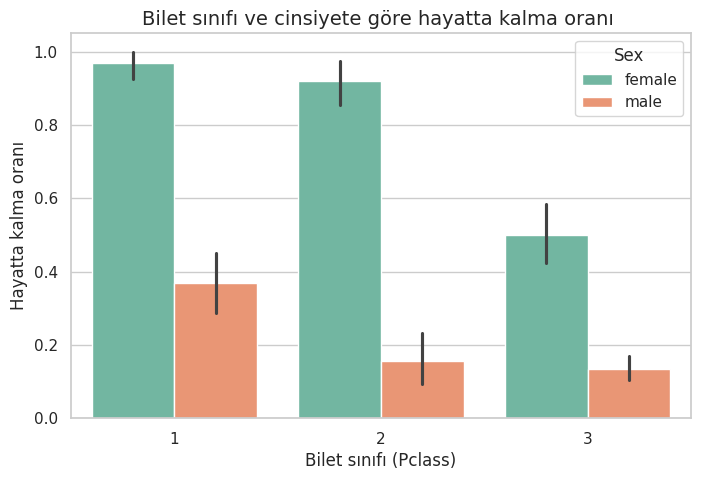

In [ ]:
plt.figure(figsize=(8,5))
sns.barplot(data=dataset, x="Pclass", y="Survived", hue="Sex", palette="Set2")
plt.title("Bilet sınıfı ve cinsiyete göre hayatta kalma oranı ",fontsize=14)
plt.xlabel("Bilet sınıfı (Pclass)")
plt.ylabel("Hayatta kalma oranı")
plt.show()

# ----------------------------------------------------------------------
# -RAPOR-
# Bu grafik bize
# -->Tüm bilet sınıflarında kadın yolcuların hayatta kalma oranı erkeklere göre çok daha yüksek olduğunu,
# -->1. sınıf yolcuların hayatta kalma ihtimali en yüksekken, 3. sınıfta bu oranın düşmekte olduğunu,
# -->Yolcunun sınıfı kurtulma şansında doğrudan belirleyici olduğunu
# anlatıyor

# -KONTROL SORUSU-
# Bu soruyu cevaplamak için neden bu grafik türünü seçtin?
# Kategorik değişkenlerin (Pclass, Sex) ikili hedef değişken (Survived) üzerindeki etkisini ve grup bazlı
#karşılaştırmayı en net gösteren yöntem Bar Chart olduğu için.


HISTOGRAM

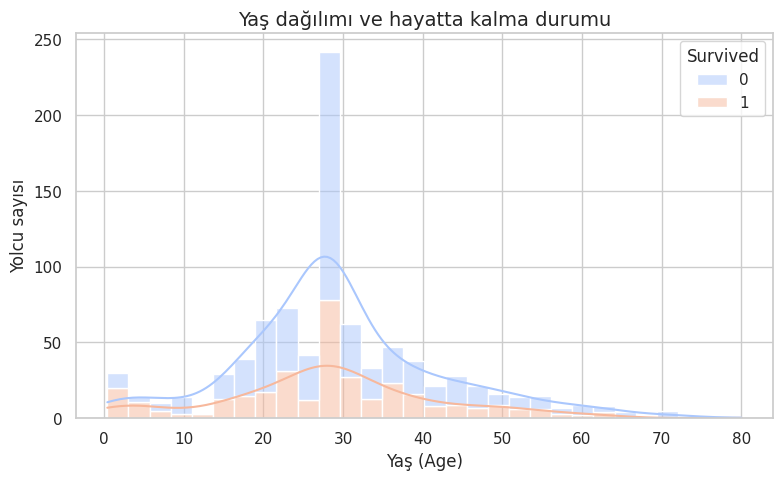

In [ ]:
plt.figure(figsize=(9,5))
sns.histplot(
    data=dataset,
    x="Age",
    hue="Survived",
    multiple="stack",
    kde=True,
    palette="coolwarm",
    bins=30,
)
plt.title("Yaş dağılımı ve hayatta kalma durumu", fontsize=14)
plt.xlabel("Yaş (Age)")
plt.ylabel("Yolcu sayısı")
plt.show()

# ----------------------------------------------------------------------
# -RAPOR-
# Bu grafik bize
# --> Gemi yolcularının çoğunluğu 20-35 yaş aralığındaki genç yetişkinlerden oluştuğunu,
# --> 0-10 yaş aralığındaki çocuk yolcularda hayatta kalma oranının yaşamını
#yitirenlere göre belirgin şekilde yüksek olduğunu,
# --> Yaş dağılımı hafif sağa çarpıktır ve yaşlı yolcu oranı oldukça düşük olduğunu
# anlatıyor.

# -KONTROL SORUSU-
# Bu soruyu cevaplamak için neden bu grafik türünü seçtin?
# Sürekli sayısal bir değişkenin (Age) frekansını, veri yoğunluğunu ve hayatta kalma durumuna göre kümelenmesini incelemek için
# en uygun araç Histogram ve KDE eğrisidir.


BOX PLOT (Kutu Grafiği / Aykırı Değer Analizi)

/tmp/ipykernel_4173/3010238915.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=dataset, x="Pclass", y="Fare", palette="Pastel1", showfliers=True)


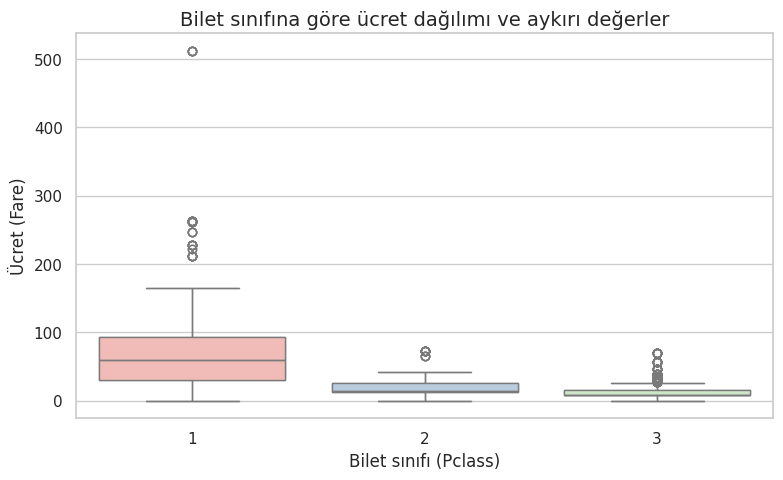

In [47]:
plt.figure(figsize=(9,5))
sns.boxplot(data=dataset, x="Pclass", y="Fare", palette="Pastel1", showfliers=True)
sns.boxplot(data=dataset, x="Pclass", y="Fare", hue="Pclass", palette="Pastel1", legend=False, showfliers=True)
plt.title("Bilet sınıfına göre ücret dağılımı ve aykırı değerler",fontsize=14)
plt.xlabel("Bilet sınıfı (Pclass)")
plt.ylabel("Ücret (Fare)")
plt.show()

# ----------------------------------------------------------------------
# -RAPOR-
# Bu grafik bize
# --> 1. sınıf bilet ücretlerinde üst sınırın çok üzerinde çok sayıda belirgin aykırı değer (500 üzeri biletler mevcuttur) bulunduğunu,
# --> 2. ve 3. sınıfların medyan ücretleri birbirine oldukça yakın ve alt seviyelerde toplandığını
#anlatıyor.

# -KONTROL SORUSU-
# Bu soruyu cevaplamak için neden bu grafik türünü seçtin?
# Veri dağılımının çeyreklik dilimlerini (Q1, Medyan, Q3) görmek ve aykırı değerleri matematiksel sınırlarıyla
#doğrudan yakalamak için Box Plot en standart grafik türüdür.


SCATTER PLOT (Saçılım Grafiği)

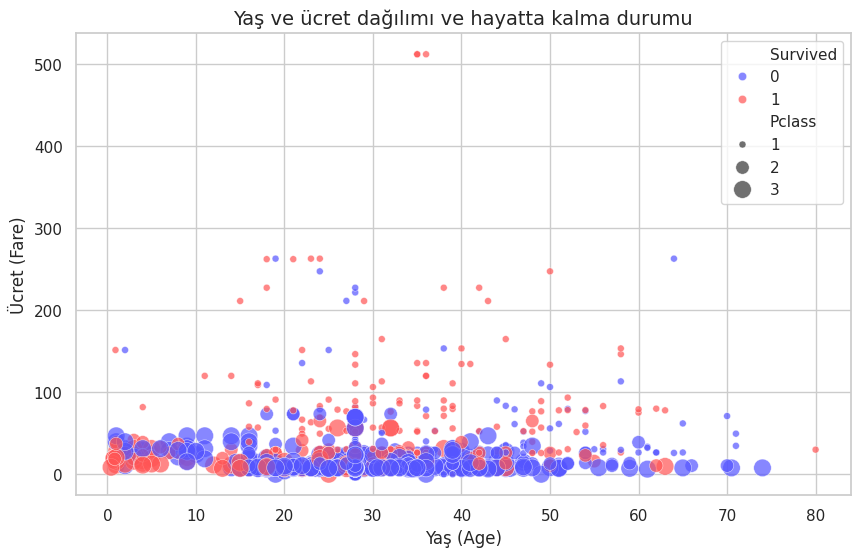

In [ ]:
plt.figure(figsize=(10,6))
sns.scatterplot(
    data=dataset,
    x="Age",
    y="Fare",
    hue="Survived",
    size="Pclass",
    sizes=(25,160),
    alpha=0.7,
    palette="seismic",
)
plt.title("Yaş ve ücret dağılımı ve hayatta kalma durumu",fontsize=14)
plt.xlabel("Yaş (Age)")
plt.ylabel("Ücret (Fare)")
plt.show()

# ----------------------------------------------------------------------
# -RAPOR-
# Bu grafik bize
# --> Yaş ile ödenen bilet ücreti arasında belirgin bir doğrusal ilişki yani korelasyon bulunmadığını,
# --> Grafiğin en üst kısmında yer alan ve çok yüksek ücret ödeyen (büyük kırmızı noktalar ve 1. sınıf hayatta kalanlar)
#yolcuların neredeyse tamamının kurtulduğunu,
# --> Düşük ücret ödeyen geniş kalabalıkta (grafiğin taban kısmı) hayatta kalamayanların yoğunlaştığını
#anlatıyor

# -KONTROL SORUSU-
# Bu soruyu cevaplamak için neden bu grafik türünü seçtin?
# İki sürekli sayısal değişken (Age ve Fare) arasındaki ilişkiyi incelerken, aynı anda renk
 #(hue=Survived) ve boyut (size=Pclass) ekleyerek 4 farklı boyutu tek bir düzlemde gözlemleyebilmek
 #için Scatter Plot tercih edildi.


# HAFTA 5: VERİ ANALİZİ VE GÖRSELLEŞTİRME (EDA RAPORU)

### 1. Veri Seti ve Ön Hazırlık Özeti
- **Kaynak ve Boyut:** 891 satır ve 11 sütundan oluşan Titanic veri seti üzerinde çalışıldı.
- **Temizleme Doğrulaması:** Age sütunundaki eksikler medyan ile, Embarked sütunundaki eksikler tepe değer (mod) ile dolduruldu. %77 oranında eksik barındıran Cabin sütunu çıkarıldı. Tüm adımlar isnull().sum() ve value_counts() kontrolleriyle teyit edildi.

### 2. Temel Bulgular ve Verinin Hikayesi
- **Cinsiyet ve Statü:** Hayatta kalma oranını belirleyen en kritik faktörler cinsiyet (Sex) ve bilet sınıfı (Pclass) olmuştur. 1. sınıf kadın yolcular en yüksek hayatta kalma oranına sahiptir.
- **Yaş Grubu:** Yolcu kitlesi ağırlıklı olarak 20-35 yaş aralığındadır. 0-10 yaş grubu çocukların tahliyesine öncelik verilmiştir.
- **Ücret Dağılımı:** Bilet ücretlerinde (Fare) belirgin bir sağa çarpıklık ve 1. sınıfa ait aşırı yüksek aykırı değerler bulunmaktadır.